# 🧭 Primeros pasos: del dato a la decisión · versión Google Colab

**Actividad introductoria guiada de Data Analytics**

En esta práctica vas a recorrer, paso a paso, el viaje completo de un dato:

| Paso | Qué haremos | Herramienta |
|---|---|---|
| 1. Cargar | Abrir una tabla de datos real | Pandas |
| 2. Limpiar | Revisar si falta algo o hay errores | Pandas y NumPy |
| 3. Preguntar | Hacer preguntas a los datos | SQL (SQLite) |
| 4. Visualizar | Convertir números en gráficos | Matplotlib |
| 5. Reflexionar | Sacar conclusiones… y ver sus límites | Tu cabeza 🙂 |

**Cómo usar este notebook**

- Un *notebook* es un cuaderno donde se mezclan explicaciones (como este texto) y celdas de código que puedes ejecutar.
- Puedes usarlo en **Google Colab** (en el navegador, sin instalar nada; es lo que usaremos en clase) o en **Visual Studio Code** (en tu ordenador; es donde se desarrolló este proyecto). Hay una versión de este notebook para cada uno; el README explica cómo abrirlos.
- Para ejecutar una celda de código: haz clic dentro de ella y pulsa **Shift + Enter**. 
- Ejecuta las celdas **en orden, de arriba abajo**. Cada celda usa lo que preparó la anterior.
- Si algo falla, no pasa nada: lee el mensaje de error, revisa la sección *Errores frecuentes* del README y vuelve a intentarlo.

> ⏱️ Duración aproximada: 90 minutos.

## 🌍 Nuestro caso: ¿qué hace que un país se sienta feliz?

Antes de tocar ningún dato, una pregunta para ti:

> 🤔 **Si tuvieras que puntuar tu vida del 0 al 10, donde 0 es la peor vida posible y 10 la mejor, ¿qué número darías? ¿Qué cosas has tenido en cuenta para decidirlo?**

Esa es, casi palabra por palabra, la pregunta que la empresa Gallup hace cada año a miles de personas en todo el mundo. Con sus respuestas se elabora el **World Happiness Report** (Informe Mundial de la Felicidad).

Hoy trabajaremos con los datos de la edición de **2016**.

## 📄 Los datos que vamos a usar

**Fuente:** *World Happiness Report 2016*, publicado en Kaggle por la Red de Soluciones para el Desarrollo Sostenible de Naciones Unidas (UN SDSN). Archivo `2016.csv`, guardado en este proyecto como `data/raw_data.csv`.

**Lo que dice la documentación del informe:**

- La puntuación de felicidad es la **media de las respuestas** de las personas encuestadas en cada país a la pregunta anterior (escala de 0 a 10).
- En la mayoría de países se encuesta a unas 1.000 personas al año, y el informe combina varios años de encuestas para que la media sea más fiable.
- El informe intenta **explicar** esa puntuación con seis factores (economía, apoyo social, salud, libertad, confianza y generosidad). Los valores de esas columnas **no son medidas directas**: indican **cuánto ayuda cada factor a explicar** la puntuación del país, comparado con un país imaginario llamado *Distopía* (lo veremos en el Paso 4).

**Cada fila es un país.** Las columnas principales son:

| Columna original | Qué significa en lenguaje sencillo |
|---|---|
| `Country` | País |
| `Region` | Región del mundo a la que pertenece |
| `Happiness Rank` | Posición en el ranking (1 = el más feliz) |
| `Happiness Score` | Puntuación media de felicidad (0 a 10) |
| `Lower / Upper Confidence Interval` | Margen de error de la puntuación: el valor real está probablemente entre estos dos números |
| `Economy (GDP per Capita)` | Cuánto explica la riqueza del país (PIB por habitante) |
| `Family` | Cuánto explica el apoyo social: tener a alguien con quien contar |
| `Health (Life Expectancy)` | Cuánto explica la esperanza de vida con buena salud |
| `Freedom` | Cuánto explica la libertad para tomar decisiones sobre la propia vida |
| `Trust (Government Corruption)` | Cuánto explica la confianza en que no hay corrupción |
| `Generosity` | Cuánto explica la generosidad (por ejemplo, donar) |
| `Dystopia Residual` | La parte de la puntuación que los seis factores **no** consiguen explicar, más el valor de referencia de Distopía |

## 📤 Antes de empezar · Sube los datos a Colab

Google Colab funciona en un ordenador de Google, en internet, que al principio está **vacío**. Tenemos que darle nuestra tabla:

1. Descarga el archivo `raw_data.csv` desde la carpeta `data` del repositorio de GitHub (botón **Download raw file**).
2. En Colab, pulsa el icono de carpeta 📁 de la barra izquierda.
3. Arrastra `raw_data.csv` a ese panel. Cuando aparezca en la lista, ya está.

> ⚠️ Los archivos que subes a Colab **se borran al cerrar la sesión**. Si vuelves otro día, súbelo de nuevo.

---
# 🧹 Etapa A · Cargar y limpiar los datos

### Paso 0 · Preparar la caja de herramientas

En programación, una **librería** es como una caja de herramientas que alguien ya ha fabricado para nosotras. Solo tenemos que «sacarla del armario» con la palabra `import`.

- **Pandas** (`pd`): para trabajar con tablas, como una hoja de cálculo pero con código.
- **NumPy** (`np`): para hacer cálculos con muchos números a la vez.
- **Matplotlib** (`plt`): para dibujar gráficos.
- **sqlite3**: para crear una pequeña base de datos y hacerle preguntas en SQL. Viene incluida con Python, no hay que instalarla.

Los nombres cortos (`pd`, `np`, `plt`) son apodos que usa casi todo el mundo para escribir menos.

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("Herramientas listas ✅")

Herramientas listas ✅


### Paso 1 · Abrir la tabla

> 🤔 **Reto:** tenemos un archivo `.csv` (un archivo de texto donde los valores se separan con comas). ¿Cómo crees que le pediremos a Python que lo abra?

Pandas tiene una instrucción llamada `read_csv` («leer CSV»). Le indicamos **dónde** está el archivo y nos devuelve un **DataFrame**: una tabla con filas y columnas, parecida a una hoja de Excel, que podemos analizar con código. La guardamos con el nombre `df`.

Como has subido el archivo a la carpeta principal de Colab, basta con escribir su nombre: `raw_data.csv`.

In [2]:
# Leemos el archivo original y lo guardamos en una tabla llamada df
df = pd.read_csv("raw_data.csv")

# .head() muestra solo las 5 primeras filas, como echar un vistazo rápido
df.head()

,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


🔎 **¿Qué ha pasado?** Python ha leído el archivo y nos muestra las cinco primeras filas. La columna de la izquierda (0, 1, 2…) es el **índice**: el número de ficha que Pandas pone a cada fila.

> 🤔 **Observa:** ¿qué país aparece primero? ¿Por qué crees que la tabla está ordenada así?

### Paso 2 · ¿Cómo de grande es la tabla y qué tipo de datos tiene?

Antes de cocinar, miramos qué hay en la nevera. Aquí haremos lo mismo:

- `df.shape` nos dice cuántas **filas** (países) y **columnas** (características) hay.
- `df.info()` nos dice el **tipo de dato** de cada columna. El tipo importa: con números se puede calcular una media, con texto no.

In [3]:
print("Filas y columnas:", df.shape)

Filas y columnas: (157, 13)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        157 non-null    str    
 1   Region                         157 non-null    str    
 2   Happiness Rank                 157 non-null    int64  
 3   Happiness Score                157 non-null    float64
 4   Lower Confidence Interval      157 non-null    float64
 5   Upper Confidence Interval      157 non-null    float64
 6   Economy (GDP per Capita)       157 non-null    float64
 7   Family                         157 non-null    float64
 8   Health (Life Expectancy)       157 non-null    float64
 9   Freedom                        157 non-null    float64
 10  Trust (Government Corruption)  157 non-null    float64
 11  Generosity                     157 non-null    float64
 12  Dystopia Residual              157 non-null    float64
dtypes

🔎 **¿Qué ha pasado?** Tenemos **157 países** y **13 columnas**.

- `Country` y `Region` son **texto** (aparecen como `str` u `object`, según la versión de Pandas).
- `Happiness Rank` es un **número entero** (`int64`).
- Las demás columnas son **números con decimales** (`float64`).

✅ **Decisión:** los tipos ya son los correctos, así que **no hace falta convertir ninguno**. Comprobarlo también es limpiar: no siempre hay que cambiar algo.

### Paso 3 · ¿Falta algún dato? (valores nulos)

Un **valor nulo** es una casilla vacía: no sabemos qué valor tiene. **No es lo mismo que un cero.** Es como un formulario donde alguien dejó una pregunta en blanco.

`df.isna()` marca cada casilla vacía y `.sum()` las cuenta por columna.

In [5]:
# Contamos cuántas casillas vacías hay en cada columna
df.isna().sum()

Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Lower Confidence Interval        0
Upper Confidence Interval        0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

🔎 **Resultado:** todas las columnas tienen **0 valores nulos**. Este archivo está completo.

Pero en la vida real los datos casi nunca llegan perfectos. Vamos a practicar con una **tabla inventada** (no forma parte de nuestros datos) para ver qué decisiones habría que tomar.

#### 🧪 Mini-reto de práctica: ¿borrar o rellenar?

Imagina una encuesta en clase sobre cuántas horas duerme cada persona. Una de ellas no contestó. Con NumPy escribimos esa casilla vacía como `np.nan` (*Not a Number*, «no es un número»).

In [6]:
# ⚠️ Tabla INVENTADA solo para practicar. No son datos del informe.
encuesta = pd.DataFrame({
    "persona": ["Ana", "Luis", "Marta", "Omar"],
    "horas_sueno": [7, 8, np.nan, 6],
})
encuesta

,persona,horas_sueno
0,Ana,7.0
1,Luis,8.0
2,Marta,NaN
3,Omar,6.0


In [7]:
# Opción 1: borrar la fila incompleta
print("Si BORRAMOS la fila:")
print(encuesta.dropna())

# Opción 2: rellenar el hueco con la media de las demás personas
media = encuesta["horas_sueno"].mean()
print("\nSi RELLENAMOS con la media (", media, "horas):")
print(encuesta.fillna({"horas_sueno": media}))

Si BORRAMOS la fila:
  persona  horas_sueno
0     Ana          7.0
1    Luis          8.0
3    Omar          6.0

Si RELLENAMOS con la media ( 7.0 horas):
  persona  horas_sueno
0     Ana          7.0
1    Luis          8.0
2   Marta          7.0
3    Omar          6.0


> 🤔 **Piensa:** ¿qué opción elegirías?

- Si **borramos**, perdemos a Marta por completo. Si faltaran muchas personas, nos quedaríamos sin datos.
- Si **rellenamos** (a esto se le llama *imputar*), conservamos a Marta, pero le estamos «inventando» un valor razonable. Eso puede esconder la realidad.

No hay una respuesta universal: depende de cuántos datos falten y de para qué los vamos a usar. Lo importante es **decidir de forma consciente y explicar por qué**.

✅ **Decisión en nuestro proyecto:** como el archivo real no tiene nulos, **no borramos ni rellenamos nada**.

### Paso 4 · Un cero no es un dato vacío

Hemos visto que no hay casillas vacías. Pero… ¿hay **ceros**? Un cero podría ser un dato real o un error disfrazado. Vamos a comprobarlo en las seis columnas de factores.

In [8]:
factores = [
    "Economy (GDP per Capita)", "Family", "Health (Life Expectancy)",
    "Freedom", "Trust (Government Corruption)", "Generosity",
]

# Para cada factor, mostramos qué país tiene exactamente un 0
for factor in factores:
    paises_con_cero = df.loc[df[factor] == 0, "Country"].tolist()
    print(f"{factor}: {paises_con_cero}")

Economy (GDP per Capita): ['Somalia']
Family: ['Togo']
Health (Life Expectancy): ['Sierra Leone']
Freedom: ['Sudan']
Trust (Government Corruption): ['Bosnia and Herzegovina']
Generosity: ['Greece']


🔎 **¿Qué ha pasado?** Hay **exactamente un cero en cada factor**, y en un país distinto cada vez. Eso no parece un error al azar, y la documentación del informe lo explica:

- El informe compara cada país con **Distopía**, un país imaginario que tiene el **valor más bajo observado** en cada factor.
- El país que tiene ese valor más bajo queda **igualado** a Distopía y por eso aparece con un 0. Por ejemplo, Somalia es el país con menor PIB por habitante de la tabla.

✅ **Decisión:** estos ceros son **datos reales**. No los tratamos como vacíos y no los cambiamos.

> 💡 Lección: antes de «limpiar», hay que **entender** qué significa cada valor.

### Paso 5 · ¿Hay filas repetidas?

Un **duplicado** es una ficha repetida, como apuntar dos veces a la misma persona en una lista. Si existiera, ese país contaría doble en los cálculos.

In [9]:
print("Filas completamente repetidas:", df.duplicated().sum())
print("Países repetidos:", df["Country"].duplicated().sum())

Filas completamente repetidas: 0
Países repetidos: 0


🔎 **Resultado:** 0 y 0. Cada país aparece una sola vez.

> 🤔 **Curiosidad:** ¿puede haber dos países con la **misma posición** en el ranking? Ejecuta la siguiente celda.

In [10]:
# keep=False muestra TODAS las filas que comparten posición
df.loc[df["Happiness Rank"].duplicated(keep=False),
       ["Country", "Happiness Rank", "Happiness Score"]]

,Country,Happiness Rank,Happiness Score
33,Saudi Arabia,34,6.379
34,Taiwan,34,6.379
56,Poland,57,5.835
57,South Korea,57,5.835
144,Burkina Faso,145,3.739
145,Uganda,145,3.739


🔎 Hay tres **empates**: los países tienen exactamente la misma puntuación, así que comparten puesto. No es un error.

✅ **Decisión:** los dejamos tal cual.

### Paso 6 · ¿Los valores tienen sentido?

La puntuación de felicidad va de 0 a 10. Si encontráramos un 15 o un −2, sería un error. Lo comprobamos con NumPy.

In [11]:
puntuaciones = df["Happiness Score"]

# np.all responde True solo si TODAS las puntuaciones cumplen la condición
dentro_de_rango = np.all((puntuaciones >= 0) & (puntuaciones <= 10))

print("¿Todas las puntuaciones están entre 0 y 10?", dentro_de_rango)
print("Mínima:", puntuaciones.min(), "| Máxima:", puntuaciones.max())

¿Todas las puntuaciones están entre 0 y 10? True
Mínima: 2.905 | Máxima: 7.526


✅ Todas las puntuaciones están dentro del rango.

**¿Filtramos alguna fila?** No. Los 157 países tienen datos completos y válidos, y queremos ver el mapa mundial completo. Quitar países sin un motivo cambiaría las conclusiones.

### Paso 7 · Poner nombres más cómodos a las columnas

Los nombres originales están en inglés y tienen espacios y paréntesis, como `Economy (GDP per Capita)`. En SQL (Etapa B), los espacios obligan a usar comillas especiales y son una fuente frecuente de errores.

✅ **Decisión:** los renombramos en español, en minúsculas y con guiones bajos `_` en lugar de espacios. **Los datos no cambian, solo las etiquetas.**

In [12]:
nombres_nuevos = {
    "Country": "pais",
    "Region": "region",
    "Happiness Rank": "ranking",
    "Happiness Score": "puntuacion",
    "Lower Confidence Interval": "intervalo_inferior",
    "Upper Confidence Interval": "intervalo_superior",
    "Economy (GDP per Capita)": "economia",
    "Family": "apoyo_social",
    "Health (Life Expectancy)": "salud",
    "Freedom": "libertad",
    "Trust (Government Corruption)": "confianza",
    "Generosity": "generosidad",
    "Dystopia Residual": "distopia_residual",
}

# Creamos una copia limpia. El DataFrame original df no se modifica
df_limpio = df.rename(columns=nombres_nuevos)
df_limpio.columns.tolist()

['pais',
 'region',
 'ranking',
 'puntuacion',
 'intervalo_inferior',
 'intervalo_superior',
 'economia',
 'apoyo_social',
 'salud',
 'libertad',
 'confianza',
 'generosidad',
 'distopia_residual']

### Paso 8 · Guardar la tabla limpia

Guardamos el resultado en un archivo nuevo, `clean_data.csv`. Aparecerá en el panel de archivos 📁 de Colab y podrás descargarlo con clic derecho → *Descargar*. **El archivo original `raw_data.csv` no se toca**: así siempre podremos volver al punto de partida.

`index=False` evita que Pandas guarde también la columna del índice (0, 1, 2…), que no es un dato real.

In [13]:
df_limpio.to_csv("clean_data.csv", index=False)
print("Guardado ✅ Filas y columnas:", df_limpio.shape)

Guardado ✅ Filas y columnas: (157, 13)


### 📋 Resumen de la limpieza

| Comprobación | Resultado | Decisión |
|---|---|---|
| Tipos de datos | Correctos | No se convierte nada |
| Valores nulos | 0 | No se borra ni se rellena nada |
| Ceros en factores | 6 (uno por factor) | Son reales (país igual a Distopía): se mantienen |
| Filas duplicadas | 0 | Nada que eliminar |
| Empates en el ranking | 3 | Son legítimos: se mantienen |
| Rango de la puntuación | 2,9 – 7,5 (dentro de 0–10) | Sin filtrado |
| Nombres de columnas | Con espacios y en inglés | Renombradas para SQL y para el aula |

> 💡 **Idea clave:** limpiar no es cambiar datos por cambiarlos. Es **comprobar, entender y decidir**, dejando por escrito el porqué.

---
# 🗄️ Etapa B · Hacer preguntas a los datos con SQL

**SQL** es un lenguaje para hacer preguntas concretas a una **base de datos**, que es un almacén ordenado de tablas. Es como hablar con un bibliotecario muy preciso: si le pides «los libros de cocina publicados después de 2010, ordenados por fecha», te los trae exactamente así.

Usaremos **SQLite**, una base de datos ligera que vive dentro de Python y no necesita instalación.

### Paso 9 · Crear la base de datos y la tabla principal

In [14]:
# Creamos una base de datos temporal en la memoria del ordenador
conexion = sqlite3.connect(":memory:")

# Copiamos nuestra tabla limpia dentro de la base de datos con el nombre "felicidad"
df_limpio.to_sql("felicidad", conexion, index=False)

print("Tabla 'felicidad' creada ✅")

Tabla 'felicidad' creada ✅


### Paso 10 · Crear una tabla auxiliar para practicar el JOIN

Nuestros datos están en **una sola tabla**, pero en el mundo real la información suele repartirse en varias. Un **JOIN** sirve para **unir dos tablas** a través de una columna que tienen en común, como unir una lista de alumnos con la lista de sus grupos usando el nombre del grupo.

Crearemos una pequeña tabla `regiones` con una utilidad real: **traducir al español** el nombre de cada región, para que los resultados se lean mejor en clase. La columna común será `region`.

In [15]:
regiones = pd.DataFrame({
    "region": [
        "Western Europe", "Central and Eastern Europe", "North America",
        "Latin America and Caribbean", "Australia and New Zealand",
        "Middle East and Northern Africa", "Sub-Saharan Africa",
        "Southeastern Asia", "Southern Asia", "Eastern Asia",
    ],
    "region_es": [
        "Europa Occidental", "Europa Central y del Este", "América del Norte",
        "América Latina y el Caribe", "Australia y Nueva Zelanda",
        "Oriente Medio y Norte de África", "África subsahariana",
        "Sudeste Asiático", "Asia del Sur", "Asia Oriental",
    ],
})
regiones.to_sql("regiones", conexion, index=False)

# Pequeña función para no repetir código: recibe una pregunta SQL y devuelve una tabla
def consulta(sql):
    return pd.read_sql_query(sql, conexion)

# Comprobación: ¿todos los países encuentran su región traducida?
consulta('''
    SELECT COUNT(*) AS paises_unidos
    FROM felicidad AS f
    JOIN regiones AS r ON f.region = r.region
''')

,paises_unidos
0,157


🔎 Salen **157 países unidos**, los mismos que tiene la tabla. Ningún país se ha quedado fuera al unir las tablas, así que la tabla auxiliar es correcta.

### ❓ Pregunta 1 · ¿Qué regiones del mundo son, de media, más felices?

**Lo que responde esta consulta:** la felicidad media de cada región y cuántos países la forman, de la más feliz a la menos feliz.

Cómo leer la consulta:

- `SELECT` → qué columnas quiero ver.
- `FROM … JOIN … ON` → de qué tablas salen y cómo se unen.
- `GROUP BY` → **agrupa** los países por región, como separar fichas en montones, y calcula un resultado por cada montón: `COUNT` cuenta y `AVG` hace la media.
- `ORDER BY … DESC` → ordena de mayor a menor.

In [16]:
pregunta_1 = consulta('''
    SELECT r.region_es              AS region,
           COUNT(*)                 AS num_paises,
           ROUND(AVG(f.puntuacion), 2) AS felicidad_media
    FROM felicidad AS f
    JOIN regiones AS r ON f.region = r.region
    GROUP BY r.region_es
    ORDER BY felicidad_media DESC
''')
pregunta_1

,region,num_paises,felicidad_media
0,Australia y Nueva Zelanda,2,7.32
1,América del Norte,2,7.25
2,Europa Occidental,21,6.69
3,América Latina y el Caribe,24,6.10
4,Asia Oriental,6,5.62
5,Oriente Medio y Norte de África,19,5.39
6,Europa Central y del Este,29,5.37
7,Sudeste Asiático,9,5.34
8,Asia del Sur,7,4.56
9,África subsahariana,38,4.14


🔎 **Interpretación:**

- **Australia y Nueva Zelanda** (7,32) y **América del Norte** (7,25) encabezan la lista, pero ojo: **cada una tiene solo 2 países**. Una media de dos valores es poco representativa.
- **Europa Occidental** (6,69, con 21 países) y **América Latina y el Caribe** (6,10, con 24 países) vienen detrás.
- **África subsahariana** (4,14) es la región con la media más baja y la que más países tiene (38).

> 🤔 ¿Te sorprende la posición de alguna región? ¿Por qué crees que importa cuántos países tiene cada grupo?

### ❓ Pregunta 2 · ¿Qué países de América Latina y el Caribe superan la media mundial de felicidad?

**Lo que responde esta consulta:** la lista de países latinoamericanos y caribeños cuya puntuación está por encima de la media de los 157 países.

- `WHERE` es un **filtro**: solo deja pasar las filas que cumplen la condición, como un colador.
- El texto `'Latin America and Caribbean'` va **entre comillas simples** porque es texto. Olvidarlas es un error muy común.
- `(SELECT AVG(puntuacion) FROM felicidad)` es una pregunta dentro de la pregunta: primero calcula la media mundial y después compara cada país con ella.

In [17]:
print("Media mundial:", round(df_limpio["puntuacion"].mean(), 2))

pregunta_2 = consulta('''
    SELECT pais, ranking, puntuacion
    FROM felicidad
    WHERE region = 'Latin America and Caribbean'
      AND puntuacion > (SELECT AVG(puntuacion) FROM felicidad)
    ORDER BY puntuacion DESC
''')
print("Países que superan la media:", len(pregunta_2))
pregunta_2

Media mundial: 5.38
Países que superan la media: 21


,pais,ranking,puntuacion
0,Costa Rica,14,7.087
1,Puerto Rico,15,7.039
2,Brazil,17,6.952
3,Mexico,21,6.778
4,Chile,24,6.705
5,Panama,25,6.701
6,Argentina,26,6.650
7,Uruguay,29,6.545
8,Colombia,31,6.481
9,Guatemala,39,6.324


🔎 **Interpretación:** **21 de los 24 países** de la región superan la media mundial (5,38). Costa Rica es el primero, en el puesto 14 del mundo. Los tres que quedan por debajo son República Dominicana, Honduras y Haití. Para comprobarlo, cambia `>` por `<=` en la consulta.

> 🤔 ¿Está tu país (o un país que conozcas) en la lista? ¿En qué posición?

### ❓ Pregunta 3 · ¿Más economía significa siempre más felicidad?

**Lo que responde esta consulta:** para las regiones con **al menos 5 países**, compara la felicidad media con cuánto aporta de media la economía a esa puntuación.

- `HAVING` es un filtro que se aplica **a los grupos**, después de agruparlos. `WHERE` filtra filas sueltas; `HAVING` filtra montones.
- Usamos `HAVING COUNT(*) >= 5` para dejar fuera las regiones de solo 2 países, cuya media es poco fiable, como vimos en la Pregunta 1.

In [18]:
pregunta_3 = consulta('''
    SELECT r.region_es                  AS region,
           COUNT(*)                     AS num_paises,
           ROUND(AVG(f.puntuacion), 2)  AS felicidad_media,
           ROUND(AVG(f.economia), 2)    AS aporte_economia_medio
    FROM felicidad AS f
    JOIN regiones AS r ON f.region = r.region
    GROUP BY r.region_es
    HAVING COUNT(*) >= 5
    ORDER BY aporte_economia_medio DESC
''')
pregunta_3

,region,num_paises,felicidad_media,aporte_economia_medio
0,Europa Occidental,21,6.69,1.42
1,Asia Oriental,6,5.62,1.28
2,Oriente Medio y Norte de África,19,5.39,1.14
3,Europa Central y del Este,29,5.37,1.05
4,América Latina y el Caribe,24,6.10,0.99
5,Sudeste Asiático,9,5.34,0.90
6,Asia del Sur,7,4.56,0.66
7,África subsahariana,38,4.14,0.47


🔎 **Interpretación:**

- En general, las regiones donde la economía aporta más tienden a ser más felices: Europa Occidental está arriba en las dos columnas y África subsahariana abajo en las dos.
- Pero hay una excepción interesante: **América Latina y el Caribe** es la **5.ª** de 8 regiones por aporte económico (0,99), pero la **2.ª** por felicidad media (6,10). Europa Central y del Este tiene un aporte económico algo mayor (1,05) y menos felicidad (5,37).

> 🤔 Si la economía no lo explica todo, ¿qué otras cosas crees que pueden influir en cómo valora la gente su vida?

---
# 📊 Etapa C · Convertir números en imágenes

Una **visualización** es una forma de dibujar los datos para que el ojo encuentre patrones que en una tabla cuestan de ver. Elegir bien el tipo de gráfico es tan importante como hacer bien los cálculos: **cada gráfico responde a un tipo de pregunta**.

Usaremos siempre los mismos colores: azul para los datos en general y naranja cuando queramos destacar algo.

In [19]:
AZUL = "#2a78d6"
NARANJA = "#eb6834"
GRIS = "#52514e"
media_mundial = df_limpio["puntuacion"].mean()

### 📊 Gráfico 1 · Felicidad media por región

**Pregunta que responde:** ¿qué regiones son, de media, más felices? Son los resultados de la Pregunta 1.

**Por qué este gráfico:** he elegido un **gráfico de barras horizontales** porque compara una cantidad entre categorías y los nombres de las regiones son largos. En horizontal se leen sin girar la cabeza. Un gráfico circular (de «quesitos») no serviría, porque las medias no son partes de un total. He añadido el número de países entre paréntesis para recordar que algunas medias se basan en muy pocos casos.

**Qué observar:** la longitud de cada barra y su posición respecto a la línea discontinua (la media mundial).

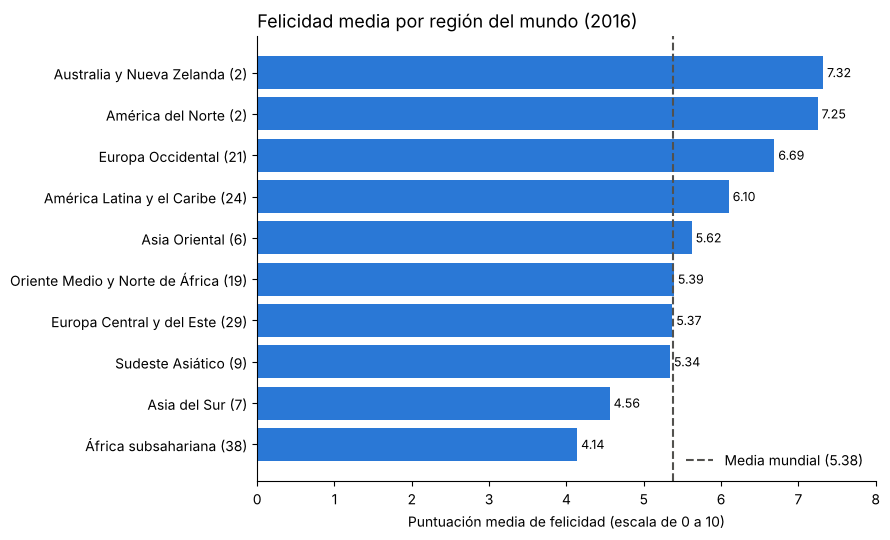

In [20]:
# Ordenamos de menor a mayor para que la barra más larga quede arriba
datos = pregunta_1.sort_values("felicidad_media")
etiquetas = datos["region"] + " (" + datos["num_paises"].astype(str) + ")"

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(etiquetas, datos["felicidad_media"], color=AZUL)
ax.axvline(media_mundial, color=GRIS, linestyle="--", linewidth=1.5,
           label=f"Media mundial ({media_mundial:.2f})")

# Escribimos el valor al final de cada barra
for y, valor in enumerate(datos["felicidad_media"]):
    ax.text(valor + 0.05, y, f"{valor:.2f}", va="center", fontsize=9)

ax.set_title("Felicidad media por región del mundo (2016)", fontsize=13, loc="left")
ax.set_xlabel("Puntuación media de felicidad (escala de 0 a 10)")
ax.set_xlim(0, 8)
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

🔎 **Qué podemos interpretar:** hay una diferencia de más de 3 puntos entre la región con mayor media y la de menor media. Seis regiones están por encima de la media mundial y cuatro por debajo, aunque Oriente Medio y Norte de África (5,39) prácticamente coincide con ella.

⚠️ **Qué NO podemos concluir:** que todas las personas de una región sean igual de felices. Una media esconde las diferencias **entre países** y **dentro de cada país**.

### 📊 Gráfico 2 · Economía y felicidad, país a país

**Pregunta que responde:** ¿los países donde la economía aporta más a la puntuación son también los más felices?

**Por qué este gráfico:** he elegido un **gráfico de dispersión** porque queremos ver la **relación entre dos números** a la vez. Cada punto es un país: su posición horizontal es el aporte de la economía y su posición vertical es su felicidad. Si los puntos forman una «nube» que sube hacia la derecha, las dos cosas tienden a ir juntas. Destaco en naranja América Latina y el Caribe para conectar con la Pregunta 3.

**Qué observar:** la forma general de la nube y dónde se sitúan los puntos naranjas respecto a los azules.

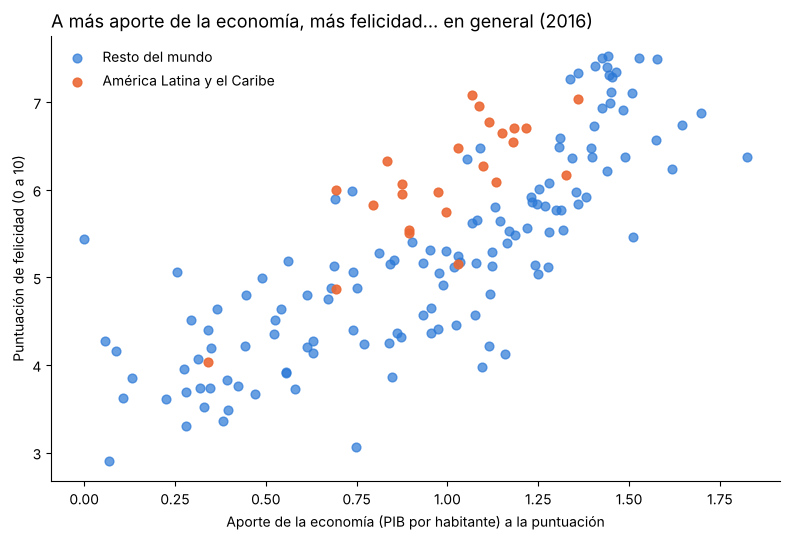

Correlación entre economía y felicidad: 0.79


In [21]:
es_latam = df_limpio["region"] == "Latin America and Caribbean"

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(df_limpio.loc[~es_latam, "economia"], df_limpio.loc[~es_latam, "puntuacion"],
           color=AZUL, alpha=0.7, s=40, label="Resto del mundo")
ax.scatter(df_limpio.loc[es_latam, "economia"], df_limpio.loc[es_latam, "puntuacion"],
           color=NARANJA, alpha=0.9, s=40, label="América Latina y el Caribe")

ax.set_title("A más aporte de la economía, más felicidad… en general (2016)",
             fontsize=13, loc="left")
ax.set_xlabel("Aporte de la economía (PIB por habitante) a la puntuación")
ax.set_ylabel("Puntuación de felicidad (0 a 10)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# La correlación mide de -1 a 1 cuánto «se mueven juntas» dos columnas
correlacion = np.corrcoef(df_limpio["economia"], df_limpio["puntuacion"])[0, 1]
print(f"Correlación entre economía y felicidad: {correlacion:.2f}")

🔎 **Qué podemos interpretar:** la nube sube hacia la derecha. La **correlación** es 0,79, un número entre −1 y 1 que indica cuánto se mueven juntas dos variables; 0,79 es una relación fuerte. Además, muchos puntos naranjas quedan **por encima** de puntos azules con un aporte económico parecido. Es lo mismo que vimos en la Pregunta 3.

⚠️ **Qué NO podemos concluir:** que el dinero **cause** la felicidad. Que dos cosas vayan juntas no significa que una provoque la otra. Por ejemplo, en verano suben a la vez las ventas de helados y las quemaduras solares, pero los helados no causan quemaduras: las dos dependen del sol. El propio informe advierte de que sus factores muestran relaciones, no causas.

### 📊 Gráfico 3 · ¿Cómo se reparten las puntuaciones?

**Pregunta que responde:** ¿la mayoría de países tienen puntuaciones altas, bajas o intermedias?

**Por qué este gráfico:** he elegido un **histograma**, que agrupa los países en tramos de puntuación (de 0,5 en 0,5) y muestra cuántos hay en cada tramo. Es como ordenar a la clase por estatura en filas: de un vistazo ves dónde se concentra la mayoría. Un gráfico de barras con 157 países sería ilegible.

**Qué observar:** dónde está la «montaña» más alta y si hay países muy alejados del resto.

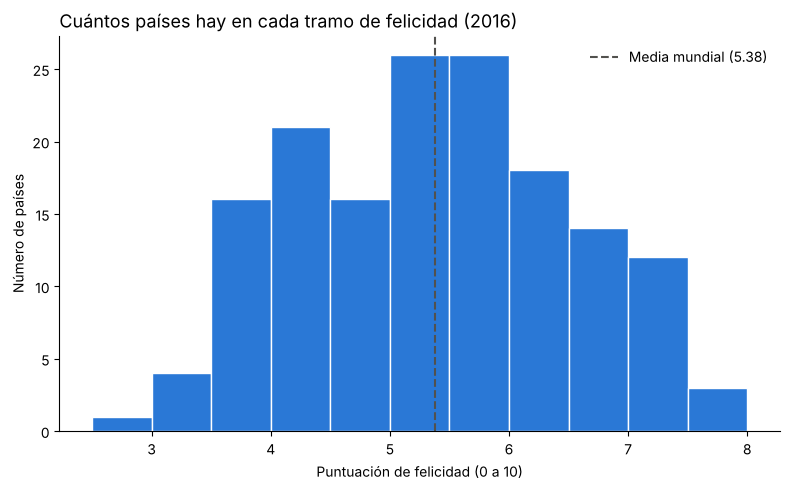

In [22]:
tramos = np.arange(2.5, 8.01, 0.5)  # límites: 2.5, 3.0, 3.5 ... 8.0

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df_limpio["puntuacion"], bins=tramos, color=AZUL, edgecolor="white")
ax.axvline(media_mundial, color=GRIS, linestyle="--", linewidth=1.5,
           label=f"Media mundial ({media_mundial:.2f})")

ax.set_title("Cuántos países hay en cada tramo de felicidad (2016)", fontsize=13, loc="left")
ax.set_xlabel("Puntuación de felicidad (0 a 10)")
ax.set_ylabel("Número de países")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

🔎 **Qué podemos interpretar:** la mayoría de países se concentra en la zona intermedia. El tramo entre 5 y 6 puntos reúne 52 de los 157 países. Ningún país llega a 8 y solo uno baja de 3 (Burundi, con 2,9).

⚠️ **Qué NO podemos concluir:** cómo se siente cada persona. Cada barra cuenta **países**, no personas. Un país pequeño y uno enorme pesan lo mismo en este gráfico.

---
# 💬 Etapa D · Del dato a la decisión: ¿qué hemos aprendido?

### Conclusiones (en lenguaje cotidiano)

1. **El lugar donde vives se refleja en cómo valoras tu vida.** Entre la región más feliz y la menos feliz hay más de 3 puntos de diferencia sobre 10. África subsahariana tiene la media más baja (4,1) y Europa Occidental, con muchos países, una de las más altas (6,7).

2. **La economía y la felicidad suelen ir de la mano, pero el dinero no lo explica todo.** Los países donde la economía aporta más suelen puntuar más alto. Sin embargo, América Latina y el Caribe tiene la segunda felicidad media más alta entre las regiones con al menos 5 países, aunque la economía le aporte menos que a otras regiones.

3. **América Latina y el Caribe destaca en positivo.** 21 de sus 24 países superan la media mundial. Curiosamente, también es la región donde los seis factores del informe dejan **más parte sin explicar** (la columna `distopia_residual` es la más alta de media). Hay algo en su bienestar que estos datos no recogen.

### ¿A quién le puede servir esta información?

- **Organizaciones sociales y de cooperación**, para recordar que el bienestar no depende solo del dinero y que el apoyo social, la salud o la libertad también cuentan.
- **Responsables de políticas públicas**, como punto de partida para preguntarse qué mejora la vida de las personas además del crecimiento económico.
- **Docentes y estudiantes**, como un caso real y cercano para aprender a preguntar a los datos con espíritu crítico.

### ⚠️ Limitaciones: lo que estos datos NO dicen

- **Es una foto de un solo momento** (el informe de 2016). No sabemos si estas diferencias se mantienen hoy.
- **Una media por país esconde desigualdades.** Dentro de un mismo país puede haber mucha diferencia entre zonas, edades o niveles de ingresos.
- **Los factores no son mediciones directas**, sino estimaciones de un modelo de cuánto ayuda cada uno a explicar la puntuación. Y muestran **relaciones, no causas**.
- **Es una sola pregunta de encuesta, respondida por una muestra** de personas. «Felicidad» aquí significa cómo valora la gente su vida en una escala del 0 al 10, no todo lo que es una vida plena.

> 🤔 **Pregunta final:** si fueras responsable de una organización social, ¿qué decisión tomarías con estos datos? ¿Y qué dato te faltaría antes de decidir?

In [23]:
# Cerramos la conexión con la base de datos: buena costumbre al terminar
conexion.close()
print("Fin de la actividad 🎉")

Fin de la actividad 🎉
